In [1]:
import math
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

# Walk up from the notebook folder to locate the repository's `code/` root
CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "models"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and models/ at or above {Path.cwd()}")

# The `beta_ols` package (and this notebook's other modules) is in `src/` next to this notebook
EXPLORATION_DIR = CODE_DIR / "papers" / "beta-loss" / "exploration"
SRC_DIR = EXPLORATION_DIR / "src"
if not (SRC_DIR / "beta_ols").is_dir():
    raise RuntimeError(f"`beta_ols` package not found in {SRC_DIR}")

# Run from `code/` and expose `code/`, `code/kev/`, and `src/` on sys.path
os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(SRC_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from dataclasses import replace

from models.kev_pointer import KevPointerModel
from training import free_gpu

import beta_ols
from beta_ols import core as beta_core
from beta_train.config import TrainConfig, scale_lr_for_sample_size
from beta_train.diagnostics import find_max_micro_chunk, gradient_check
from beta_train.items import build_items_cached, items_summary
from beta_train.model_state import set_checkpointing, snapshot_trainable
from beta_train.reports import comparison_table, eval_beta_table, mse_decomposition, per_dataset_table
from beta_train.trainer import RunResult, run_training
from beta_train.validation import PopulationValidator, TrainingPathValidator, validate_all_cached, validation_metrics_frame

# Disk cache for training items and the untrained (step-0) validation; delete the folder to clear it
CACHE_DIR = CODE_DIR / ".cache" / "beta_training"

print(f"CODE_DIR: {CODE_DIR}")

CODE_DIR: /home/dw/github/decision-models-finetuning/code


In [2]:
# Require CUDA and release any previously loaded `kev_model` before allocating a fresh backbone
if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is required to train Kev in bf16")
if "kev_model" in globals():
    globals().pop("kev_model")
device = "cuda"
free_gpu()
torch.manual_seed(42)

# Model settings (also the key of the cached step-0 validation)
KEV_BASE = "jaredpalmer/kev-9b"
LORA_RANK = 64
WEIGHTS_DTYPE = "bf16"
HEAD_TEMPERATURE = 1.0   # training uses raw uncalibrated temperature = 1.0
GRADIENT_CHECKPOINTING = True   # recompute activations in backward: needed to fit the 9B backbone; used by every run

# Build the frozen backbone + LoRA + pointer head
t_model0 = time.perf_counter()
kev_model = KevPointerModel.build(
    KEV_BASE,
    device=device,
    lora_rank=LORA_RANK,
    weights_dtype=WEIGHTS_DTYPE,
)
kev_model.net.head.temperature = HEAD_TEMPERATURE
kev_model.train()                     # enable training mode (LoRA dropout active, trainable params require_grad)
set_checkpointing(kev_model, GRADIENT_CHECKPOINTING)
torch.cuda.synchronize()
model_load_sec = time.perf_counter() - t_model0

trainable_params_count = sum(p.numel() for p in kev_model.trainable_parameters())
total_params_count = sum(p.numel() for p in kev_model.parameters())
display(
    pd.Series(
        {
            "base_model": KEV_BASE,
            "mode": kev_model.mode,
            "training": kev_model.training,
            "weights_dtype": kev_model.meta.weights_dtype,
            "lora_rank": kev_model.meta.lora,
            "trainable_params": f"{trainable_params_count:,}",
            "total_params": f"{total_params_count:,}",
            "gradient_checkpointing": GRADIENT_CHECKPOINTING,
            "model_load_sec": round(model_load_sec, 3),
        },
        name="kev_train_mode",
    ).to_frame()
)

# Snapshot the untrained trainable weights right after building, so every run, diagnostic, and the step-0
# validation start from them (rebuilding the model re-snapshots)
INIT_TRAINABLE_STATE = snapshot_trainable(kev_model)
MODEL_KEY = {"base": KEV_BASE, "lora_rank": LORA_RANK, "weights_dtype": WEIGHTS_DTYPE, "head_temperature": HEAD_TEMPERATURE}
print(f"Snapshotted {len(INIT_TRAINABLE_STATE)} trainable tensors")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/427 [00:00<?, ?it/s]

,kev_train_mode
base_model,jaredpalmer/kev-9b
mode,lora_rank 64
training,True
weights_dtype,bf16
lora_rank,64
trainable_params,"175,211,008"
total_params,"8,111,895,552"
gradient_checkpointing,True
model_load_sec,3.095


Snapshotted 500 trainable tensors


# Datasets (loaded and replicated through `beta_ols`)

In [3]:
# Datasets this notebook uses; only these are loaded (the others are skipped to save time)
ITEM_DATASETS = [         # training items are built for these (training, gradient check, VRAM search)
    # "wu2025",
    # "berke2023",
    "grummon2023",
]
VALIDATION_DATASETS = [   # validation runs on these
    "grummon2025",
]
LOADED_DATASETS = list(ITEM_DATASETS)
for dataset_name in VALIDATION_DATASETS:
    if dataset_name not in LOADED_DATASETS:
        LOADED_DATASETS.append(dataset_name)

# Load each through its `beta_ols` module: task rows, regression rows, regression specs, human OLS replication.
# Validation uses the whole dataset. Training splits a dataset with several task variables (`v`) into one pseudo
# dataset per task ("<dataset>/<v>"), so an item holds one respondent's tasks of a single kind.
choice_dfs: dict[str, pd.DataFrame] = {}
regression_rows_by_dataset: dict[str, pd.DataFrame] = {}
regression_specs_by_dataset: dict[str, dict] = {}
human_ols_by_dataset: dict[str, pd.DataFrame] = {}
module_by_dataset = {}    # (pseudo) dataset name -> the beta_ols module that codes its rows
TRAIN_DATASETS = []       # pseudo datasets of ITEM_DATASETS, the names training uses

for dataset_name in LOADED_DATASETS:
    dataset_module = beta_ols.DATASET_MODULES[dataset_name]
    full_choice_df = dataset_module.load_choice_df()
    pieces = {}
    if dataset_name in VALIDATION_DATASETS:
        pieces[dataset_name] = full_choice_df
    if dataset_name in ITEM_DATASETS:
        task_pieces = beta_core.split_by_task(full_choice_df, dataset_name)
        pieces.update(task_pieces)
        TRAIN_DATASETS.extend(task_pieces)

    for piece_name, choice_df in pieces.items():
        rows = dataset_module.regression_rows(choice_df)
        specs = dataset_module.regression_specs(rows)
        module_by_dataset[piece_name] = dataset_module
        choice_dfs[piece_name] = choice_df
        regression_rows_by_dataset[piece_name] = rows
        regression_specs_by_dataset[piece_name] = specs
        human_ols_by_dataset[piece_name] = beta_core.fit_human_ols(rows, specs)
        print(f"{piece_name}: {choice_df['CASEID'].nunique():,} respondents | {len(choice_df):,} tasks | {len(specs)} regression(s)")
        display(beta_core.wide_ols_table(human_ols_by_dataset[piece_name]).round(4))
print(f"TRAIN_DATASETS = {TRAIN_DATASETS}")


grummon2023: 7,943 respondents | 15,886 tasks | 2 regression(s)


grummon2023/bev                  grummon2023/snack                 
                                       beta      se std_beta              beta      se std_beta
Green vs Calorie                   -34.1531  4.0874  -0.2968          -12.7322  2.3247  -0.1923
TrafficLight vs Calorie            -31.4715  4.1171  -0.2735          -13.6485  2.3449  -0.2061
PhysicalActivity vs Calorie        -39.0136  4.0531  -0.3390          -18.4529  2.4394  -0.2787
Warning vs Calorie                 -28.1985  4.0934  -0.2450          -14.2004  2.4201  -0.2145
sigma_y                            115.0825     NaN      NaN           66.2099     NaN      NaN
n_rows                            7943.0000     NaN      NaN         7943.0000     NaN      NaN

grummon2025: 5,633 respondents | 33,798 tasks | 1 regression(s)


grummon2025                 
                                          beta      se std_beta
NutritionInfo vs Positive               0.1844  0.0119   0.4196
HighIn vs Positive                      0.0541  0.0122   0.1231
Positive+NutritionInfo vs Positive      0.1788  0.0120   0.4069
Positive+HighIn vs Positive             0.1194  0.0122   0.2718
Spectrum vs Positive                    0.1083  0.0125   0.2464
sigma_y                                 0.4395     NaN      NaN
n_rows                              33798.0000     NaN      NaN

# Model, validators, and training items

In [6]:
# One validator per VALIDATION_DATASETS entry (population OLS from the dataset's module); pick how inference runs
VALIDATOR_KIND = "fused"   # "fused": LoRA merged + fused kernels + CUDA graphs, persona states shared
                           # "training_path": the training forward in eval mode, LoRA unmerged (no merge/offload/capture)
# "fused" per-GPU-batch inference budgets: lower them if validation runs out of memory (bigger models), raise for speed
VALIDATION_MAX_QUESTIONS = 1024
VALIDATION_MAX_CHARS = 1_000_000
# "training_path" items (data rows) per forward pass (no gradients, so far above the training micro-chunk)
VALIDATION_EVAL_CHUNK = 16

validators = {}
if VALIDATOR_KIND == "fused":
    for dataset_name in VALIDATION_DATASETS:
        validators[dataset_name] = PopulationValidator(
            beta_ols.DATASET_MODULES[dataset_name],
            choice_dfs[dataset_name],
            regression_specs_by_dataset[dataset_name],
            max_questions=VALIDATION_MAX_QUESTIONS,
            max_chars=VALIDATION_MAX_CHARS,
        )
elif VALIDATOR_KIND == "training_path":
    # The training path runs on items (tokenized respondents), cached on disk like the training items
    validation_modules = {}
    for dataset_name in VALIDATION_DATASETS:
        validation_modules[dataset_name] = beta_ols.DATASET_MODULES[dataset_name]
    validation_items, validation_items_report = build_items_cached(kev_model, validation_modules, choice_dfs, cache_dir=CACHE_DIR)
    display(validation_items_report)
    for dataset_name in VALIDATION_DATASETS:
        validators[dataset_name] = TrainingPathValidator(
            beta_ols.DATASET_MODULES[dataset_name],
            choice_dfs[dataset_name],
            regression_specs_by_dataset[dataset_name],
            validation_items[dataset_name],
            eval_chunk=VALIDATION_EVAL_CHUNK,
        )
else:
    raise ValueError(f"VALIDATOR_KIND must be 'fused' or 'training_path', got {VALIDATOR_KIND!r}")
display(pd.DataFrame([validator.describe() for validator in validators.values()]).set_index("validator"))

,kind,tasks,packed_persona_states,regressions,max_questions,max_chars,prep_sec
validator,,,,,,,
grummon2025,fused,33798,4906,grummon2025,1024,1000000,6.271


In [7]:
# Untrained (step-0) validation, loaded from the disk cache when it already ran for this model, data, and code;
# reused as the first validation row of every run
step0_validation, step0_cache_report = validate_all_cached(
    kev_model,
    validators,
    INIT_TRAINABLE_STATE,
    model_key=MODEL_KEY,
    cache_dir=CACHE_DIR,
)
display(step0_cache_report)
display(validation_metrics_frame(step0_validation).round(4))
for dataset_name, (_, beta_df) in step0_validation.items():
    display(beta_df.round(4))

Evaluating grummon2025_validation (shared-state):   0%|          | 0/35 [00:00<?, ?batch/s]

KeyboardInterrupt: 

In [7]:
# Tokenize the TRAIN_DATASETS rows into training items (one per data row), loaded from the disk cache when they were already
# built for this data, tokenizer, and code; Kev's prepared targets are checked against each respondent's beta part

item_modules = {}
for dataset_name in TRAIN_DATASETS:
    item_modules[dataset_name] = module_by_dataset[dataset_name]
unified_items, items_cache_report = build_items_cached(kev_model, item_modules, choice_dfs, cache_dir=CACHE_DIR)
display(items_cache_report)
display(items_summary(unified_items, regression_specs_by_dataset))

items: grummon2023:   0%|          | 0/7943 [00:00<?, ?it/s]

,respondents,source
dataset,,
grummon2023,7943,built


,respondents,tasks,regression_groups
dataset,,,
grummon2023,7943,15886,"grummon2023/bev, grummon2023/snack"


# Find max micro chunk

In [ ]:
# Largest micro-chunk (items = data rows per chunk) that fits in VRAM for the worst-case (most padded) chunks of these datasets
SEARCH_GRADIENT_CHECKPOINTING = GRADIENT_CHECKPOINTING   # search with the setting you train with
SEARCH_MAX_CHUNK = 64
SEARCH_CANDIDATES_PER_SIZE = 3          # worst-case chunks tested per size; a size fits only if all of them fit

search_items = []
for dataset_name in TRAIN_DATASETS:
    search_items.extend(unified_items[dataset_name])
micro_chunk_search_df, MAX_FITTING_MICRO_CHUNK = find_max_micro_chunk(
    kev_model,
    search_items,
    INIT_TRAINABLE_STATE,
    max_chunk=SEARCH_MAX_CHUNK,
    gradient_checkpointing=SEARCH_GRADIENT_CHECKPOINTING,
    candidates_per_size=SEARCH_CANDIDATES_PER_SIZE,
)
display(micro_chunk_search_df)
print(f"gradient_checkpointing={SEARCH_GRADIENT_CHECKPOINTING} | MAX_FITTING_MICRO_CHUNK = {MAX_FITTING_MICRO_CHUNK}")

# Train

In [ ]:
MAX_FITTING_MICRO_CHUNK = 6
SEARCH_GRADIENT_CHECKPOINTING = GRADIENT_CHECKPOINTING

In [ ]:
# Base run settings; each run cell below changes only beta_lambda
BASE_LR_SAMPLE_1 = 2e-5   # validated 1-respondent/step LR; scaled by sqrt(sample size)
SAMPLE_SIZE = 256

BASE_CONFIG = TrainConfig(
    train_datasets=tuple(TRAIN_DATASETS),
    sample_size_by_dataset={ts: SAMPLE_SIZE for ts in TRAIN_DATASETS},
    beta_lambda=0.0,
    lr=scale_lr_for_sample_size(BASE_LR_SAMPLE_1, 128),
    num_epochs=5,
    eval_every=31,
    lr_schedule="onecycle",
    weight_decay=0.01,
    micro_chunk=MAX_FITTING_MICRO_CHUNK,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
)
# Show a per-step bar over the micro-chunk passes (pass 1 forward, pass 2 forward + backward)
SHOW_CHUNK_PROGRESS = True
runs: dict[str, RunResult] = {}
display(pd.Series(BASE_CONFIG.as_dict(), name="base_config").to_frame())

In [17]:
# Run BASE_CONFIG with beta_lambda = 0
beta_lambda = 0.0
run_config = replace(BASE_CONFIG, beta_lambda=beta_lambda)
runs[f"lambda={run_config.beta_lambda:g}"] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    show_chunk_progress=SHOW_CHUNK_PROGRESS,
)

NameError: name 'INIT_TRAINABLE_STATE' is not defined

,epoch,respondents_seen,train_loss,grummon2025/kl_loss,grummon2025/beta_mse,grummon2025/beta_mae,grummon2025/beta_mape_pct,grummon2025/spearman_rho,lr,grummon2025/eval_wall_sec,train_elapsed_sec
step,,,,,,,,,,,
0,0,0,NaN,1.0589,0.00546,0.0651,64.72026,0.5,NaN,67.66931,0.0


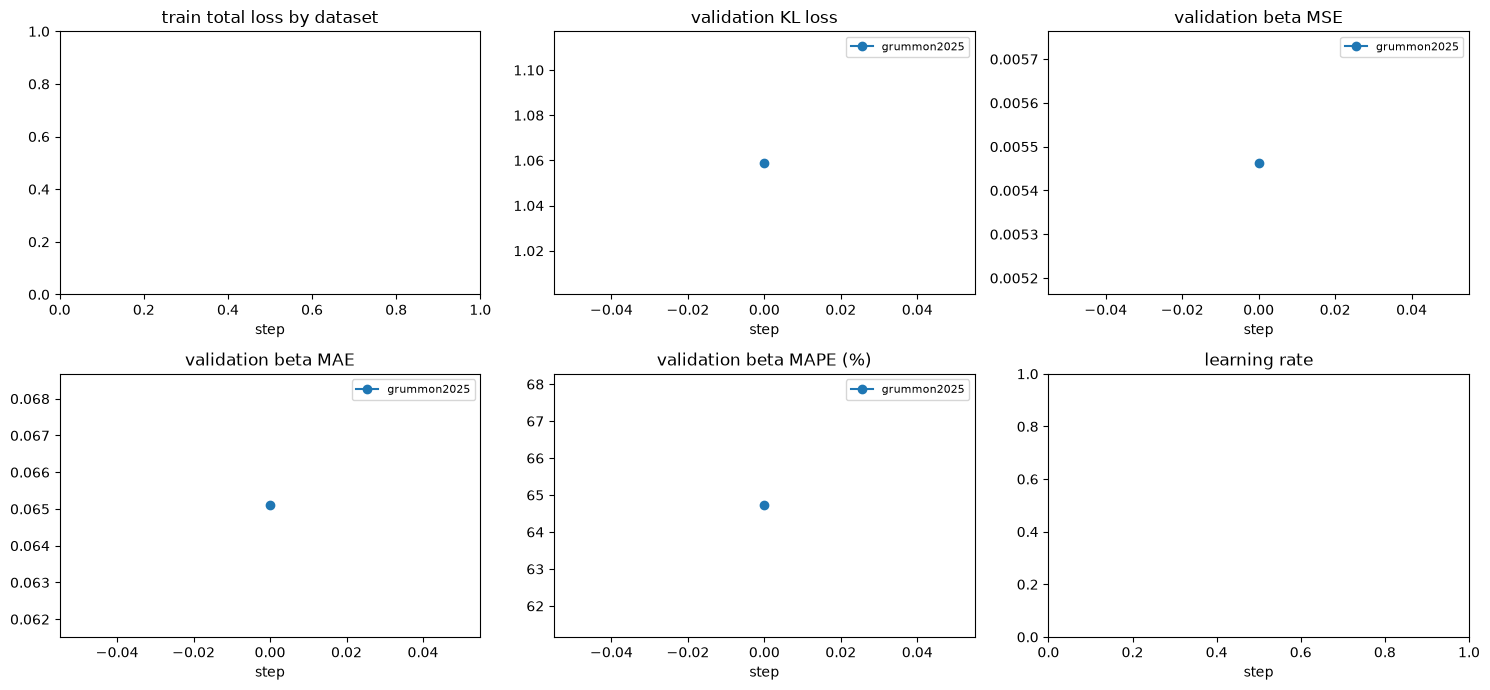

grummon2023 | lambda=0.25:   0%|          | 0/160 [00:00<?, ?it/s]

In [ ]:
beta_lambda = 0.25
run_config = replace(BASE_CONFIG, beta_lambda=beta_lambda)
runs[f"lambda={run_config.beta_lambda:g}"] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    show_chunk_progress=SHOW_CHUNK_PROGRESS,
)

In [ ]:
beta_lambda = 1.00
run_config = replace(BASE_CONFIG, beta_lambda=beta_lambda)
runs[f"lambda={run_config.beta_lambda:g}"] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    show_chunk_progress=SHOW_CHUNK_PROGRESS,
)

In [ ]:
# Run BASE_CONFIG with beta_lambda = 3
run_config = replace(BASE_CONFIG, beta_lambda=4.0)
runs[f"lambda={run_config.beta_lambda:g}"] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    show_chunk_progress=SHOW_CHUNK_PROGRESS,
)

In [ ]:
# Run BASE_CONFIG with beta_lambda = 4
run_config = replace(BASE_CONFIG, beta_lambda=4.0)
runs[f"lambda={run_config.beta_lambda:g}"] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    show_chunk_progress=SHOW_CHUNK_PROGRESS,
)

In [ ]:
# Run BASE_CONFIG with beta_lambda = 5
run_config = replace(BASE_CONFIG, beta_lambda=5.0)
runs[f"lambda={run_config.beta_lambda:g}"] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    show_chunk_progress=SHOW_CHUNK_PROGRESS,
)

In [ ]:
# Run BASE_CONFIG with beta_lambda = 20
run_config = replace(BASE_CONFIG, beta_lambda=20.0)
runs[f"lambda={run_config.beta_lambda:g}"] = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=run_config,
    device=device,
    show_chunk_progress=SHOW_CHUNK_PROGRESS,
)

In [ ]:
# Compare finished runs: final validation metrics, per-dataset train losses, and each validator's betas
display(comparison_table(runs, step0_validation).round(5))
display(per_dataset_table(runs).round(5))
for dataset_name in validators:
    display(eval_beta_table(runs, step0_validation, dataset_name).round(4))

In [ ]:
# Decompose each validator's beta MSE into per-beta squared errors across runs
for dataset_name in validators:
    display(mse_decomposition(runs, step0_validation, dataset_name).round(5))

# Cross-dataset beta scale and sample-size target noise

In [ ]:
# Compare raw vs sigma_y-standardized human beta mean-square across the loaded datasets
scale_rows = []
for dataset_name, tidy in human_ols_by_dataset.items():
    choice_df = choice_dfs[dataset_name]
    option_counts = sorted({len(one_hot) for one_hot in choice_df["one_hot"]})
    sigma_by_model = tidy.groupby("model", sort=False)["sigma_y"].first()
    scale_rows.append(
        {
            "dataset": dataset_name,
            "respondents": choice_df["CASEID"].nunique(),
            "tasks": len(choice_df),
            "options_per_task": ", ".join(str(n) for n in option_counts),
            "regressions": len(sigma_by_model),
            "num_betas": len(tidy),
            "sigma_y": ", ".join(f"{sigma:.4g}" for sigma in sigma_by_model),
            "raw_signal_beta_ms": float((tidy["human_beta"] ** 2).mean()),
            "std_signal_beta_ms": float((tidy["std_beta"] ** 2).mean()),
        }
    )
display(pd.DataFrame(scale_rows).set_index("dataset").round(5))

In [ ]:
# Target noise of sample betas vs row sample size (Monte Carlo over data rows = training items), per regression
SNR_DATASET = "grummon2023"   # must be in LOADED_DATASETS
SNR_SAMPLE_SIZES = [16, 32, 64, 128, 256]
SNR_DRAWS = 4000

beta_noise_df = beta_core.beta_noise_by_sample_size(
    regression_rows_by_dataset[SNR_DATASET],
    regression_specs_by_dataset[SNR_DATASET],
    SNR_SAMPLE_SIZES,
    SNR_DRAWS,
    seed=42,
)
display(beta_noise_df.set_index(["model", "sample_size"]).round(4))

# Test micro-batching

In [ ]:
# Two-pass micro-chunked gradient (training) vs one backward through the whole sample
CHECK_DATASET = "grummon2023"   # any key of `unified_items`
CHECK_SAMPLE_SIZE = 15          # one graph of this many items (rows) must fit in VRAM (method A)
CHECK_MICRO_CHUNK = 3           # items (data rows) per chunk
CHECK_BETA_LAMBDA = 5.0         # > 0 so both KL and beta gradients are tested

gradient_check_result = gradient_check(
    kev_model,
    unified_items[CHECK_DATASET],
    regression_specs_by_dataset[CHECK_DATASET],
    INIT_TRAINABLE_STATE,
    sample_size=CHECK_SAMPLE_SIZE,
    micro_chunk=CHECK_MICRO_CHUNK,
    beta_lambda=CHECK_BETA_LAMBDA,
    seed=0,
    device=device,
)
display(pd.Series(gradient_check_result, name="gradient_check").to_frame())

# Overfit first

In [ ]:
# Overfit sanity check: many passes with pure KL/CE, constant LR, and zero weight decay
BASE_LR_SAMPLE_1 = 2e-5   # validated 1-respondent/step LR; scaled by sqrt(sample size)

OVERFIT_CONFIG = TrainConfig(
    train_datasets=("grummon2023",),
    sample_size_by_dataset={"grummon2023": 128},
    beta_lambda=0.0,
    lr=scale_lr_for_sample_size(BASE_LR_SAMPLE_1, 128),
    num_epochs=10,
    eval_every=math.ceil(len(unified_items["grummon2023"]) / 128),   # one validation per epoch
    lr_schedule="constant",
    weight_decay=0.0,
    micro_chunk=MAX_FITTING_MICRO_CHUNK,
    gradient_checkpointing=GRADIENT_CHECKPOINTING,
    grad_clip=1.0,
    seed=42,
)
overfit_run = run_training(
    model=kev_model,
    items_by_dataset=unified_items,
    specs_by_dataset=regression_specs_by_dataset,
    validators=validators,
    step0_validation=step0_validation,
    init_snapshot=INIT_TRAINABLE_STATE,
    config=OVERFIT_CONFIG,
    device=device,
    show_chunk_progress=SHOW_CHUNK_PROGRESS,
)